# Electricity MFA – Holmen Hallsta Paper Mill, 2023

**Energy and exergy flow analysis of electricity-related flows, with constrained Monte Carlo uncertainty and improvement measures.**

This notebook is the explained walkthrough of the model. Run it top to bottom (*Kernel → Restart & Run All*). The last cell calls the same `build_all()` that `analysis/run_model.py` uses, so the notebook, the CSV tables in `reports/tables/` and the figures in `reports/figures/` always agree.

| Step | What happens | Section |
|---|---|---|
| 1 | Extract and tag every raw number (source id, year, quality class) | §1 |
| 2 | Convert everything to GWh/y | §2 |
| 3 | Resolve conflicting data and fix conventions | §3 |
| 4 | Fill gaps (residuals and assumptions) and build the balance | §4 |
| 5 | Balance checks and independent cross-checks, Sankey | §5 |
| 6 | Exergy factors and hotspots | §6 |
| 7 | Constrained Monte Carlo, sensitivity, scenarios | §7 |
| 8 | Improvement measures M1–M4 | §8 |

**Scope:** electricity (plus 2.82 GWh diesel as an energy input) · 2023 · GWh/y · Hallsta site fence · reference temperature T0 = 7 °C.

**Sources:** every input carries an id from `data/sources.csv` (see `data/README.md`). Every class C/D assumption is listed in `docs/assumptions.md`. The audit that led to this version is `docs/review/model_audit.md`; what changed is in `docs/review/model_changes.md`.

## How to read this notebook

**The question in one sentence:** the mill buys 1,450 GWh of electricity in 2023. *Where does every kilowatt-hour end up, and which step wastes the most useful energy?*

**The idea in plain words.** Think of the electricity bill as money in a household budget. Some goes to rent (the big refiners), some to groceries (paper machines), and a few small items. Nobody gave us the full budget, so we collect every number we can find, check them against each other, fill the holes with "whatever is left over", and make sure the books balance to zero.

**Material Flow Analysis (MFA)** is exactly that bookkeeping: draw boxes (processes), draw arrows (flows) between them, and make sure *what goes in = what comes out* for every box.

**Reading tips**
- Every section starts with **Intuition** (plain language), then the **Formula**, then the **code**.
- The code lives in the package `src/hallsta_mfa/` (`model.py` the balance, `mc.py` Monte Carlo, `measures.py` improvement measures, `outputs.py` tables and figures, all tested in `tests/`). This notebook calls it and explains it.
- Run it with `uv sync && uv run jupyter lab` (see the README).

### Glossary

| Term | Meaning |
|---|---|
| **GWh/y** | Gigawatt-hours per year. 1 GWh = 1,000 MWh = 1,000,000 kWh. A household uses ~5 MWh/y, so 1 GWh is about 200 households. |
| **TMP** | Thermo-Mechanical Pulp. Wood chips are ground between steam-heated steel discs. Very electricity-hungry, and the grinding turns most of that electricity into heat. |
| **PM** | Paper machine. Presses and dries the pulp into paper. The drying uses steam. |
| **Electric boiler** | A kettle on industrial scale: electricity heats water into steam. |
| **WWTP** | Waste-water treatment plant. |
| **Steam network** | The pipes that carry steam from where it is made (TMP heat recovery, boilers) to where it is used (PM drying). |
| **Residual / gap-filling** | When one flow is unknown, set it to *total minus all the known flows*. It absorbs every error, so treat it as the least certain number. |
| **Energy** | The *quantity* of energy. It is never destroyed, only moved. |
| **Exergy** | The *quality* of energy: how much of it could still do useful work. Electricity is pure exergy. Lukewarm water has almost none. |
| **T0 (dead state)** | The surroundings temperature (here 7 °C). Heat at T0 has zero exergy because it cannot drive anything. |
| **Monte Carlo** | Re-run the model thousands of times with randomly drawn inputs to see how much the answer moves. |
| **Triangular / normal / uniform** | Three shapes for "how sure am I about this input": a most-likely value with limits, a bell curve, or "anywhere in this range". |
| **P5 / P50 / P95** | The 5th, 50th (median) and 95th percentiles of the Monte Carlo results. 90% of runs fall between P5 and P95. |
| **Spearman ρ** | A number from -1 to +1 that says how strongly two things move together (by rank). |
| **Constrained Monte Carlo** | Only runs that agree with Holmen's data are kept: TMP supplies 70–90 % of steam, the steam residual is not negative and no exergy destruction is negative. |
| **COP** | Coefficient of performance of a heat pump: heat delivered per unit of electricity. |
| **Class A/B/C/D** | Data quality: A measured 2023, B recent estimate, C older or indirect, D our own assumption. |

In [1]:
# Setup. The model lives in src/hallsta_mfa/ so the maths can be tested.
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import CoolProp.CoolProp as CP
from IPython.display import Image, HTML, display
from hallsta_mfa import plotstyle, outputs as O
from hallsta_mfa.model import BASE, DIST, PROCS, f_sens, steam_v, run, label, ppf, SEC_TMP_NORMAL
from hallsta_mfa.mc import evaluate, run_mc, summary
from hallsta_mfa.measures import MEASURES, evaporated_water

plotstyle.use()
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.max_colwidth', 90); pd.set_option('display.width', 200)
src = pd.read_csv(Path('..') / 'data' / 'sources.csv').set_index('id')   # the source register

## 1. Extract and tag the raw data
**Intuition.** Before calculating anything, write down every number with its *receipt*: the id of the row in `data/sources.csv` it came from, the year, and how much we trust it. A measured 2023 value is worth more than a 2019 email answer.

**Quality classes:** **A** measured/reported for 2023 (MR2023) · **B** recent Holmen estimate (2025 answers) · **C** older (2019) or indirect · **D** our own assumption (no data). Nothing is converted yet.

In [2]:
# (id in this notebook, description, value, unit, source id in data/sources.csv, class)
RAW = [
 ('E_tot',    'Total electricity use',                       1450,    'GWh/y',     'el_total_2023_t13',          'A'),
 ('diesel',   'Diesel, internal transport',                  2.82,    'GWh/y',     'diesel_gwh_2023_t13',        'A'),
 ('paper_t',  'Paper production',                            444494,  't/y',       'prod_paper_2023',            'A'),
 ('pulp_t',   'TMP pulp production',                         421883,  't/y',       'prod_tmp_2023',              'A'),
 ('DH_MWh',   'Excess heat to Norrtälje Energi',             11877,   'MWh/y',     'dh_export_2023',             'A'),
 ('Q_wwtp',   'Flow from WWTP to recipient',                 18300,   'm3/d',      'effluent_wwtp_daily_2023',   'A'),
 ('V_total',  'Total effluent, both outlets',                7288861, 'm3/y',      'effluent_total_2023',        'A'),
 ('V_cool',   'Release of cooling water and other non-affected process waters (2024 data)', 4.0, 'Mm3/y', 'img_wb_cooling', 'B'),
 ('days_PM11','PM11 operating days',                         285.3,   'd',         'pm11_days_2023',             'A'),
 ('days_PM12','PM12 operating days',                         314,     'd',         'pm12_days_2023',             'A'),
 ('sh_TMP_25','TMP share of electricity',                    70,      '%',         'el_split_tmp_2025',          'B'),
 ('sh_PM_25', 'Paper machines share',                        15,      '%',         'el_split_pm_2025',           'B'),
 ('sh_EB_25', 'Electric boilers share',                      10,      '%',         'el_split_boiler_2025',       'B'),
 ('sh_TMP_19','TMP share (3-yr avg)',                        72,      '%',         'el_split_tmp_2019',          'C'),
 ('sh_PM_19', 'Paper machines share (3-yr avg)',             22,      '%',         'el_split_pm_2019',           'C'),
 ('sh_EB_19', 'Electric boilers share (3-yr avg)',           6,       '%',         'el_split_boiler_2019',       'C'),
 ('P_wood',   'Wood handling electricity',                   2.5,     'MW',        'wood_handling_el_2025',      'B'),
 ('P_bleach', 'Bleaching electricity',                       3.0,     'MW',        'bleaching_el_2025',          'B'),
 ('P_wwtp',   'WWTP electricity',                            2.5,     'MW',        'wwtp_el_2025',               'B'),
 ('aux_TMP',  'TMP auxiliary drives',                        150,     'kWh/t',     'tmp_aux_el_2025',            'B'),
 ('SEC_norm', 'Normal TMP refining energy (range 1,500-2,000)', 2000, 'kWh/t',    'tmp_el_spec_2025',           'B'),
 ('m_rec',    'Steam recycled from TMP',                     100,     't/h',       'tmp_steam_recycled_2025',    'B'),
 ('y_EB',     'Steam per MW electric boiler (cross-check only)', 1.5, 't/MWh',     'steam_per_MW_2025',          'B'),
 ('m_PM',     'Steam to PM drying (80-110)',                 95,      't/h',       'pm_steam_2025',              'B'),
 ('m_wood',   'Steam to wood handling',                      1.5,     't/h',       'wood_handling_steam_2025',   'B'),
 ('rec_range','Steam recovery covers 70-90 % of need',       80,      '%',         'steam_recovery_rate_2025',   'B'),
 ('p_steam_g','Steam pressure (2.4 bar(g), 138 C)',          2.4,     'bar(g)',    'steam_pressure_pm_2019',     'C'),
 ('T_cond',   'Condensate from PM',                          90,      'C',         'condensate_temp_pm_2019',    'C'),
 ('TMP3_19',  'TMP3 electricity (Aug 2019)',                 46000,   'MWh/month', 'el_tmp3_aug2019',            'C'),
 ('TMP12_19', 'TMP12 electricity (Aug 2019)',                38000,   'MWh/month', 'el_tmp12_aug2019',           'C'),
 ('PM11_19',  'PM11 + bleaching (Aug 2019)',                 14000,   'MWh/month', 'el_pm11_aug2019',            'C'),
 ('PM12_19',  'PM12 + bleaching (Aug 2019)',                 8000,    'MWh/month', 'el_pm12_aug2019',            'C'),
 ('steamTMP_19','Net steam production TMP (period not stated)', 145000, 'GJ',      'steam_tmp_net_2019',         'C'),
 ('steamPM_19','Steam use paper machines (period not stated)', 155000, 'GJ',       'steam_pm_2019',              'C'),
 ('wwtp_19',  'WWTP share of electricity',                   1.25,    '%',         'el_wwtp_share_2019',         'C'),
 ('T_PMww',   'PM waste water temperature',                  50,      'C',         'pm_wastewater_T_2019',       'C'),
 ('dT_eff',   'Effluent "32 degrees above sea" (pre-2020 WWTP)', 32,  'K or C',    'effluent_dT_sea_2019',       'C'),
 ('fibre',    'Fibre content of paper (80-88 %)',            84,      '%',         'paper_fibre_aq',             'C'),
 ('fin_moist','Water content of paper',                      7,       '%',         'paper_water_aq',             'B'),
]
raw = pd.DataFrame(RAW, columns=['id','description','value','unit','source_id','class']).set_index('id')
raw

,description,value,unit,source_id,class
id,,,,,
E_tot,Total electricity use,"1,450.00",GWh/y,el_total_2023_t13,A
diesel,"Diesel, internal transport",2.82,GWh/y,diesel_gwh_2023_t13,A
paper_t,Paper production,"444,494.00",t/y,prod_paper_2023,A
pulp_t,TMP pulp production,"421,883.00",t/y,prod_tmp_2023,A
DH_MWh,Excess heat to Norrtälje Energi,"11,877.00",MWh/y,dh_export_2023,A
Q_wwtp,Flow from WWTP to recipient,"18,300.00",m3/d,effluent_wwtp_daily_2023,A
V_total,"Total effluent, both outlets","7,288,861.00",m3/y,effluent_total_2023,A
V_cool,Release of cooling water and other non-affected process waters (2024 data),4.00,Mm3/y,img_wb_cooling,B
days_PM11,PM11 operating days,285.30,d,pm11_days_2023,A


In [3]:
raw.groupby('class').size().rename('number of raw values').to_frame()

,number of raw values
class,
A,9
B,15
C,15


In [4]:
# Spot check: the source ids really exist in the register (and show what they say)
missing = [i for i in raw.source_id if i not in src.index]
print('ids missing from data/sources.csv:', missing)
src.loc[['effluent_dT_sea_2019','img_wb_cooling','steam_recovery_rate_2025','tmp_el_spec_2025'], ['quantity','value','value_low','value_high','unit','quote']]

ids missing from data/sources.csv: []


,quantity,value,value_low,value_high,unit,quote
id,,,,,,
effluent_dT_sea_2019,temperature difference WWTP effluent vs sea,32.00,NaN,NaN,degC,Roughly 32 degrees most of the time.
img_wb_cooling,water balance: release of cooling and other non-affected process waters,4.00,NaN,NaN,Mm3/yr,4 Million m³/year
steam_recovery_rate_2025,steam recovery rate of need,NaN,70.00,90.00,%,the recovery rate is about 70-90% of the needed consumption
tmp_el_spec_2025,TMP refining specific electricity,NaN,"1,500.00","2,000.00",kWh/t,somewhere between 1500 and 2000 kWh/tonne


## 2. Convert everything to GWh/y
**Intuition.** The sources speak in MW, tonnes of steam per hour, GJ per month, kWh per tonne and so on. To add or compare flows they must all be in the same unit. Think of converting euros, dollars and kronor to one currency before summing a budget.

**Formulas.** Power × time = energy: $E_{GWh} = P_{MW} \times h / 1000$. Steam: $E = \dot m \times h \times \Delta h / 1000$, where $\Delta h$ is the energy released by one tonne of steam when it condenses and cools.

**A worked example (wood handling).** 2.5 MW running 7,200 h = 2.5 × 7,200 / 1000 = **18 GWh/y**. The code below does this for every row.

## 2. Convert everything to GWh/y

| Raw unit | Rule to GWh/y |
|---|---|
| MW (power) | MW × running hours / 1,000 |
| t/h of steam | t/h × hours × Δh / 1,000, where Δh = energy per tonne of steam |
| boiler efficiency η | sampled directly; implied yield = η / Δh (t steam per MWh), cross-checked against Holmen's 1.5 t/MWh |
| GJ/month | × 12 / 3,600 |
| MWh/month | × 12 / 1,000 |
| % of electricity | % × 1,450 GWh |
| m³ of warm water | m³ × ρcp × ΔT / 3.6·10⁶ |
| kWh/t | × tonnes / 10⁶ |

**Running hours.** Tabell 4: PM11 285.3 d and PM12 314 d. Production-weighted (233,453 t and 211,041 t) this is 298.9 d = **7,174 h**, rounded to **7,200 h** (class C, derived). One shared draw per MC run drives TMP and PM steam, because Holmen says the TMP lines follow PM demand. The WWTP ran 365 d (8,760 h).

**Steam energy Δh (decision 1).** The base keeps the *property-based* basis: saturated steam at 3.4 bar abs (2.4 bar(g), 138 °C) condensed to 90 °C condensate, about 2.35 GJ/t. The alternative "latent heat only, 2.15 GJ/t" is run as scenario S5 in §7e.

In [5]:
T0 = 7.0
h_prod, h_wwtp = BASE['h_prod'], BASE['h_wwtp']
p_abs = (raw.loc['p_steam_g','value'] + 1.0) * 1e5   # Pa  (2.4 bar(g) -> 3.4 bar abs)
dh, fx_steam = steam_v(p_abs, raw.loc['T_cond','value'], T0)
Tsat = CP.PropsSI('T','P',p_abs,'Q',1,'Water') - 273.15
print(f'Saturation temperature at 3.4 bar abs: {Tsat:.1f} °C (Holmen: ~138 °C)')
print(f'Δh = {dh:.4f} MWh/t = {dh*3.6:.3f} GJ/t   (latent heat only would be 2.15 GJ/t)')
print(f'Exergy factor of this steam = {fx_steam:.3f}')
print(f"Production-weighted operating time: {(233453*285.3 + 211041*314)/(233453+211041)*24:,.0f} h")

Saturation temperature at 3.4 bar abs: 137.8 °C (Holmen: ~138 °C)
Δh = 0.6537 MWh/t = 2.353 GJ/t   (latent heat only would be 2.15 GJ/t)
Exergy factor of this steam = 0.315
Production-weighted operating time: 7,174 h


In [6]:
MW_to_GWh    = lambda MW, hours: MW * hours / 1000
steam_to_GWh = lambda t_per_h, hours: t_per_h * hours * dh / 1000
GJm_to_GWh   = lambda GJ_month: GJ_month * 12 / 3600
MWhm_to_GWh  = lambda MWh_month: MWh_month * 12 / 1000
E = raw.loc['E_tot','value']
conv = pd.DataFrame([
 ('Wood handling',        '2.5 MW',             'MW × 7,200 h',            MW_to_GWh(2.5, h_prod)),
 ('Bleaching',            '3 MW',               'MW × 7,200 h',            MW_to_GWh(3.0, h_prod)),
 ('WWTP',                 '2.5 MW',             'MW × 8,760 h',            MW_to_GWh(2.5, h_wwtp)),
 ('TMP auxiliaries',      '150 kWh/t',          'kWh/t × 421,883 t',       150 * raw.loc['pulp_t','value'] / 1e6),
 ('Recovered TMP steam',  '100 t/h',            't/h × 7,200 h × Δh',      steam_to_GWh(100, h_prod)),
 ('PM drying steam',      '95 t/h',             't/h × 7,200 h × Δh',      steam_to_GWh(95, h_prod)),
 ('Wood handling steam',  '1.5 t/h',            't/h × 7,200 h × Δh',      steam_to_GWh(1.5, h_prod)),
 ('District heat',        '11,877 MWh',         '/ 1,000',                 raw.loc['DH_MWh','value'] / 1000),
 ('Cooling water heat',   '4.0 Mm³ × 10 K (assumed)', 'm³ × 4.17 MJ/m³K × ΔT / 3.6e6', 4.0e6*4.17*10/3.6e6),
 ('TMP (2019 check)',     '46,000 + 38,000 MWh/month', '× 12 / 1,000',     MWhm_to_GWh(46000 + 38000)),
 ('TMP steam (2019 check)', '145,000 GJ (per month?)', '× 12 / 3,600',     GJm_to_GWh(145000)),
 ('PM steam (2019 check)',  '155,000 GJ (per month?)', '× 12 / 3,600',     GJm_to_GWh(155000)),
], columns=['flow','raw value','conversion','GWh/y'])
conv

,flow,raw value,conversion,GWh/y
0,Wood handling,2.5 MW,"MW × 7,200 h",18.00
1,Bleaching,3 MW,"MW × 7,200 h",21.60
2,WWTP,2.5 MW,"MW × 8,760 h",21.90
3,TMP auxiliaries,150 kWh/t,"kWh/t × 421,883 t",63.28
4,Recovered TMP steam,100 t/h,"t/h × 7,200 h × Δh",470.68
5,PM drying steam,95 t/h,"t/h × 7,200 h × Δh",447.14
6,Wood handling steam,1.5 t/h,"t/h × 7,200 h × Δh",7.06
7,District heat,"11,877 MWh","/ 1,000",11.88
8,Cooling water heat,4.0 Mm³ × 10 K (assumed),m³ × 4.17 MJ/m³K × ΔT / 3.6e6,46.33
9,TMP (2019 check),"46,000 + 38,000 MWh/month","× 12 / 1,000","1,008.00"


## 3. Resolve conflicting data
**Intuition.** Two sources disagree, like two friends giving different split-the-bill percentages. We pick one as the *baseline*, say why, and keep the other to test later, so the choice is visible and not hidden. Each decision below is recorded in `docs/assumptions.md`.

**Conflict 1: two different electricity splits** (2019 vs 2025).

In [7]:
split = pd.DataFrame({'2019 answer (3-yr avg)': [72, 22, 6, 0], '2025 answer': [70, 15, 10, 5]},
                     index=['TMP', 'Paper machines incl. bleaching', 'Electric boilers', 'Other users'])
split['difference (pp)'] = split['2025 answer'] - split['2019 answer (3-yr avg)']
split

,2019 answer (3-yr avg),2025 answer,difference (pp)
TMP,72,70,-2
Paper machines incl. bleaching,22,15,-7
Electric boilers,6,10,4
Other users,0,5,5


**Decision:** the 2025 split is the **baseline** (closer to 2023, given with the annual total). The 2019 split is scenario S1. The "other" 5 % is only the remainder, not a Holmen number. The named items (wood 2.5 MW × 7,200 h, WWTP 2.5 MW × 8,760 h, grid loss 1 %) add up to about 54 GWh = 3.75 %, so `sh_OTH` is sampled as triangular(4 %, 5 %, 7 %).

**Conflict 2: is the pulp tonnage air-dry or bone-dry?** A fibre balance settles it.

In [8]:
paper, pulp = raw.loc['paper_t','value'], raw.loc['pulp_t','value']
fibre_in_paper = paper * raw.loc['fibre','value'] / 100
for basis, dry in [('air-dry (90% dry)', 0.90), ('bone-dry (100% dry)', 1.00)]:
    dry_fibre = pulp * dry
    print(f'{basis:20s}: dry fibre in pulp {dry_fibre:,.0f} t vs fibre in paper {fibre_in_paper:,.0f} t -> difference {dry_fibre/fibre_in_paper-1:+.1%}')
print('Fibre losses are only ~2–3%, so the tonnage is air-dry (ADT).')

air-dry (90% dry)   : dry fibre in pulp 379,695 t vs fibre in paper 373,375 t -> difference +1.7%
bone-dry (100% dry) : dry fibre in pulp 421,883 t vs fibre in paper 373,375 t -> difference +13.0%
Fibre losses are only ~2–3%, so the tonnage is air-dry (ADT).


**Conflict 3: steam heat basis.** Property-based 2.35 GJ/t (base) against latent-heat-only 2.15 GJ/t. Base stays property-based because the condensate returns at 90 °C; the latent-only basis is scenario S5.

**Conflict 4: effluent temperature.** The 2019 source says "roughly 32 degrees above sea". That is ambiguous (ΔT to the sea, or absolute), it pre-dates the 2020 WWTP rebuild, and an absolute 32–35 °C is physically more plausible for a biological WWTP. Base: **T_eff = 35 °C absolute**, uniform 30–40 °C. Reading it as 32 K above a 7 °C sea (39 °C) is scenario S7.

**Conflict 5: PM waste temperature.** Source says "around 50": base is now **50 °C** (was 55), range 45–60.

**Conflict 6: TMP specific energy.** The 70 % share gives 2,406 kWh/t, 12 % above Holmen's normal 1,500–2,000 (+150 auxiliaries). Either the share, the tonnage basis or 2023 operation (many stops) differs. It is shown as a cross-check and as scenario S6; the "gap" lever is conditional on the 70 % share being right.

## 4. Fill the gaps and build the balance
**Intuition.** Three numbers nobody measured are set to "what is left over" (the *gaps*): utilities & other electricity, steam to hot water/heating/venting, and heat to air. Because the leftovers absorb all errors, the books balance **by construction**. The cross-checks in §5b are what tell us whether the result is believable. The steam residual is **not** plugged or corrected: its label is *Steam to hot water, heating and venting (unallocated)* everywhere.

| Layer | Question | Main formula | Gap (residual) |
|---|---|---|---|
| 1. Electricity end uses | Where does the 1,450 GWh go? | share × total, or power × hours | Utilities & other = other bucket minus named items |
| 2. Steam loop | Where does steam come from and go? | tonnes/h × hours × Δh | Steam unallocated = supply − PM − wood − losses |
| 3. Final sinks | Where does the energy end up? | volume × cp × ΔT | Heat to air = (electricity + diesel) − effluent − cooling water − district heat |

**Electric boiler.** The efficiency η is sampled directly (triangular 0.95/0.98/0.995) instead of drawing a yield and multiplying by Δh (that product exceeded 1 in 6 % of runs). The implied yield η/Δh ≈ 1.50 t/MWh is an *output*, cross-checked against Holmen.

**Formula for heat in water:** $Q = V \cdot \rho c_p \cdot (T - T_{ref})$. Cooling water (4.0 Mm³/y) has no source for its temperature rise: base 10 K, uniform 5–15 K (class D).

In [9]:
O.inputs_table()

,param,description,value,unit,distribution,source_id,data_class
0,E_tot,Electricity use 2023,"1,450.00",GWh/y,"normal(mean 1450, sd 14.5)",el_total_2023_t13,A
1,paper_t,Paper production,"444,494.00",t/y,"normal(mean 444494, sd 4444.94)",prod_paper_2023,A
2,pulp_t,TMP pulp production (ADT),"421,883.00",t/y,"normal(mean 421883, sd 4218.83)",prod_tmp_2023,A
3,DH_export,District heat to Norrtalje Energi,11.88,GWh/y,"normal(mean 11.877, sd 0.59385)",dh_export_2023,A
4,diesel,"Diesel, internal transport (energy input, heat ends in air)",2.82,GWh/y,"normal(mean 2.82, sd 0.0564)",diesel_gwh_2023_t13,A
5,V_wwtp,"WWTP effluent volume (18,300 m3/d x 365)","6,679,500.00",m3/y,"normal(mean 6.6795e+06, sd 333975)",effluent_wwtp_daily_2023,A
6,V_ff,Second outlet FF PM2 = total effluent - WWTP,"609,361.00",m3/y,"normal(mean 609361, sd 60936.1)",effluent_total_2023,A
7,V_cool,Release of cooling water and other non-affected process waters,"4,000,000.00",m3/y,"normal(mean 4e+06, sd 400000)",img_wb_cooling,B
8,dT_cool,Temperature rise of cooling water (NOT in any source),10.00,K,"uniform(5, 15)",assumption,D
9,sh_TMP,TMP share of electricity,0.70,-,"triangular(0.65, 0.7, 0.75)",el_split_tmp_2025,B


In [10]:
b = evaluate(dict(BASE))
print('TMP electricity by hand :', 1450 * 0.70, 'GWh   | model:', round(b['el_TMP'], 3))
print('Steam energy per tonne (dh):', round(b['dh'], 4), 'MWh/t')
print('Electricity check:', round(sum(b[k] for k in ['el_TMP','el_PM','el_bleach','el_EB','el_wood','el_wwtp','el_util','el_dist']), 6), 'GWh (must equal 1,450)')
print(f"k-guard (named items scaled down): k = {b['k_oth']:.2f} at base")

TMP electricity by hand : 1014.9999999999999 GWh   | model: 1015.0
Steam energy per tonne (dh): 0.6537 MWh/t
Electricity check: 1450.0 GWh (must equal 1,450)
k-guard (named items scaled down): k = 1.00 at base


### Layer 1: where the electricity goes

In [11]:
L1 = pd.DataFrame({'GWh/y': [b['el_TMP_ref'], b['el_TMP_aux'], b['el_PM'], b['el_EB'], b['el_wwtp'], b['el_bleach'],
                             b['el_util'], b['el_wood'], b['el_dist']]},
                  index=['TMP refiners','TMP auxiliary drives','Paper machines','Electric boilers','WWTP','Bleaching',
                         'Utilities & other (residual)','Wood handling','Internal grid losses'])
L1['share'] = (L1['GWh/y']/E).map('{:.1%}'.format)
L1.loc['TOTAL'] = [L1['GWh/y'].sum(), f"{L1['GWh/y'].sum()/E:.0%}"]
L1

,GWh/y,share
TMP refiners,951.72,65.6%
TMP auxiliary drives,63.28,4.4%
Paper machines,195.90,13.5%
Electric boilers,145.00,10.0%
WWTP,21.90,1.5%
Bleaching,21.60,1.5%
Utilities & other (residual),18.10,1.2%
Wood handling,18.00,1.2%
Internal grid losses,14.50,1.0%
TOTAL,"1,450.00",100%


### Layer 2: the steam loop

In [12]:
L2 = pd.Series({'Recovered TMP steam': b['st_rec'], 'Electric-boiler steam': b['st_EB'], '= Steam supply': b['st_supply'],
                'to PM drying': b['st_PM'], 'to wood handling': b['st_wood'], 'network losses (4%)': b['st_loss'],
                'Steam to hot water, heating and venting (unallocated)': b['st_HW']}, name='GWh/y').to_frame()
L2

,GWh/y
Recovered TMP steam,470.68
Electric-boiler steam,142.10
= Steam supply,612.78
to PM drying,447.14
to wood handling,7.06
network losses (4%),24.51
"Steam to hot water, heating and venting (unallocated)",134.06


In [13]:
print(f"Electric boiler efficiency : {b['eff_EB']:.1%}  -> implied yield {b['y_EB_implied']:.3f} t/MWh (Holmen: 1.5)")
print(f"TMP heat recovered as steam: {b['TMP_rec_eff']:.1%} of TMP electricity")
print(f"Share of steam from TMP    : {b['rec_ratio']:.1%}")

Electric boiler efficiency : 98.0%  -> implied yield 1.499 t/MWh (Holmen: 1.5)
TMP heat recovered as steam: 46.4% of TMP electricity
Share of steam from TMP    : 76.8%


### Layer 3: final sinks
All the energy ends as heat: to effluent water, to cooling water, to district heating (useful), or to air. Diesel (2.82 GWh) is an extra input whose heat ends in air.

In [14]:
L3 = pd.Series({'Heat to effluent water': b['sink_water'], 'Heat to cooling water': b['sink_cool'], 'District heating export': b['sink_DH'],
                'Heat to air (residual)': b['sink_air']}, name='GWh/y').to_frame()
L3['share of input'] = (L3['GWh/y']/b['E_in']).map('{:.1%}'.format)
print(f"Total energy input = electricity {E:,.0f} + diesel {BASE['diesel']:.2f} = {b['E_in']:,.2f} GWh")
L3

Total energy input = electricity 1,450 + diesel 2.82 = 1,452.82 GWh


,GWh/y,share of input
Heat to effluent water,232.87,16.0%
Heat to cooling water,46.33,3.2%
District heating export,11.88,0.8%
Heat to air (residual),"1,161.74",80.0%


## 5. Balance checks and cross-checks
**Intuition.** Two different tests. A **balance check** asks "does the arithmetic add up?" It must be exactly 0 or we have a bug, but because the residuals were *defined* to close, it cannot detect wrong inputs. A **cross-check** compares our result with a number we did *not* use to build the model. The only non-tautological balance is the plant-level exergy closure.

In [15]:
checks = pd.Series({
  'Layer 1: E − sum of end uses': E - sum(b[k] for k in ['el_TMP','el_PM','el_bleach','el_EB','el_wood','el_wwtp','el_util','el_dist']),
  'Layer 2: supply − sum of steam uses': b['st_supply'] - (b['st_PM']+b['st_wood']+b['st_loss']+b['st_HW']),
  'Layer 3: (E + diesel) − sum of sinks': b['E_in'] - (b['sink_water']+b['sink_cool']+b['sink_DH']+b['sink_air']),
  'Exergy: E − (destroyed + waste + useful hot water)': E - (b['Xdest_total'] + b['Xwaste_total'] + b['Xuse|Hot water & heating'])}, name='residual (GWh/y)')
assert (checks.abs() < 1e-6).all()
checks.to_frame()

,residual (GWh/y)
Layer 1: E − sum of end uses,0.00
Layer 2: supply − sum of steam uses,0.00
Layer 3: (E + diesel) − sum of sinks,-0.00
Exergy: E − (destroyed + waste + useful hot water),0.00


In [16]:
xc = O.crosschecks(b).set_index('quantity'); xc[['model','independent','unit','diff_pct','source_id','note']]

,model,independent,unit,diff_pct,source_id,note
quantity,,,,,,
TMP electricity,"1,015.00","1,008.00",GWh/y,0.69,el_tmp3_aug2019+el_tmp12_aug2019,one month (Aug 2019) x 12
PM + bleaching electricity,217.50,264.00,GWh/y,-17.61,el_pm11_aug2019+el_pm12_aug2019,one month (Aug 2019) x 12
Recovered TMP steam,470.68,483.33,GWh/y,-2.62,steam_tmp_net_2019,"145,000 GJ read as per month (period not stated in source; conflicts with steam_tmp3_u..."
PM drying steam,447.14,516.67,GWh/y,-13.46,steam_pm_2019,"155,000 GJ read as per month (period not stated)"
WWTP share of electricity,1.51,1.25,%,20.83,el_wwtp_share_2019,midpoint of 1-1.5 %
Share of steam from TMP,76.81,80.00,%,-3.99,steam_recovery_rate_2025,midpoint of 70-90 %
Mill specific electricity,3.26,3.30,MWh/t paper,-1.15,spec_energy_2023_t13,NOT independent: same electricity and tonnage
Total energy input (electricity + diesel),"1,452.82","1,453.00",GWh/y,-0.01,energy_sum_2023_t13,NOT independent: built from the same table
TMP specific energy vs upper normal range,"2,405.88","2,150.00",kWh/t,11.90,tmp_el_spec_2025+tmp_aux_el_2025,"Holmen normal 1,500-2,000 + 150 aux; model above the range (audit S1)"


**Reading the cross-checks.** TMP electricity, recovered TMP steam and the boiler yield agree well. The paper-machine steam is 13 % below the 2019 figure (the 2019 numbers have no stated period). Two rows are *not independent* (mill specific use and total energy come from the same MR2023 table). Two rows flag real tensions: the TMP specific energy is above Holmen's normal range, and the steam residual (134 GWh) is about eight times the documented heat uses (DH 11.9 GWh plus roughly 4.4 GWh domestic heating in 2019), so most of it is steam we cannot place.

### 5c. Energy Sankey
**Intuition.** Bands whose width is proportional to the flow. Start at the left with grid electricity and follow the bands to where the energy ends up. The interactive HTML version is saved next to the PNG in `reports/figures/`.

,source,target,GWh/y
0,Grid electricity,TMP plant,"1,015.00"
1,Grid electricity,Electric boilers,145.00
2,Grid electricity,Paper machines,195.90
3,Grid electricity,Other users*,94.10
4,Diesel,Low-grade waste heat,2.82
5,TMP plant,Steam network,470.68
6,Electric boilers,Steam network,142.10
7,TMP plant,Low-grade waste heat,544.32
8,Electric boilers,Low-grade waste heat,2.90
9,Steam network,Paper machines,447.14


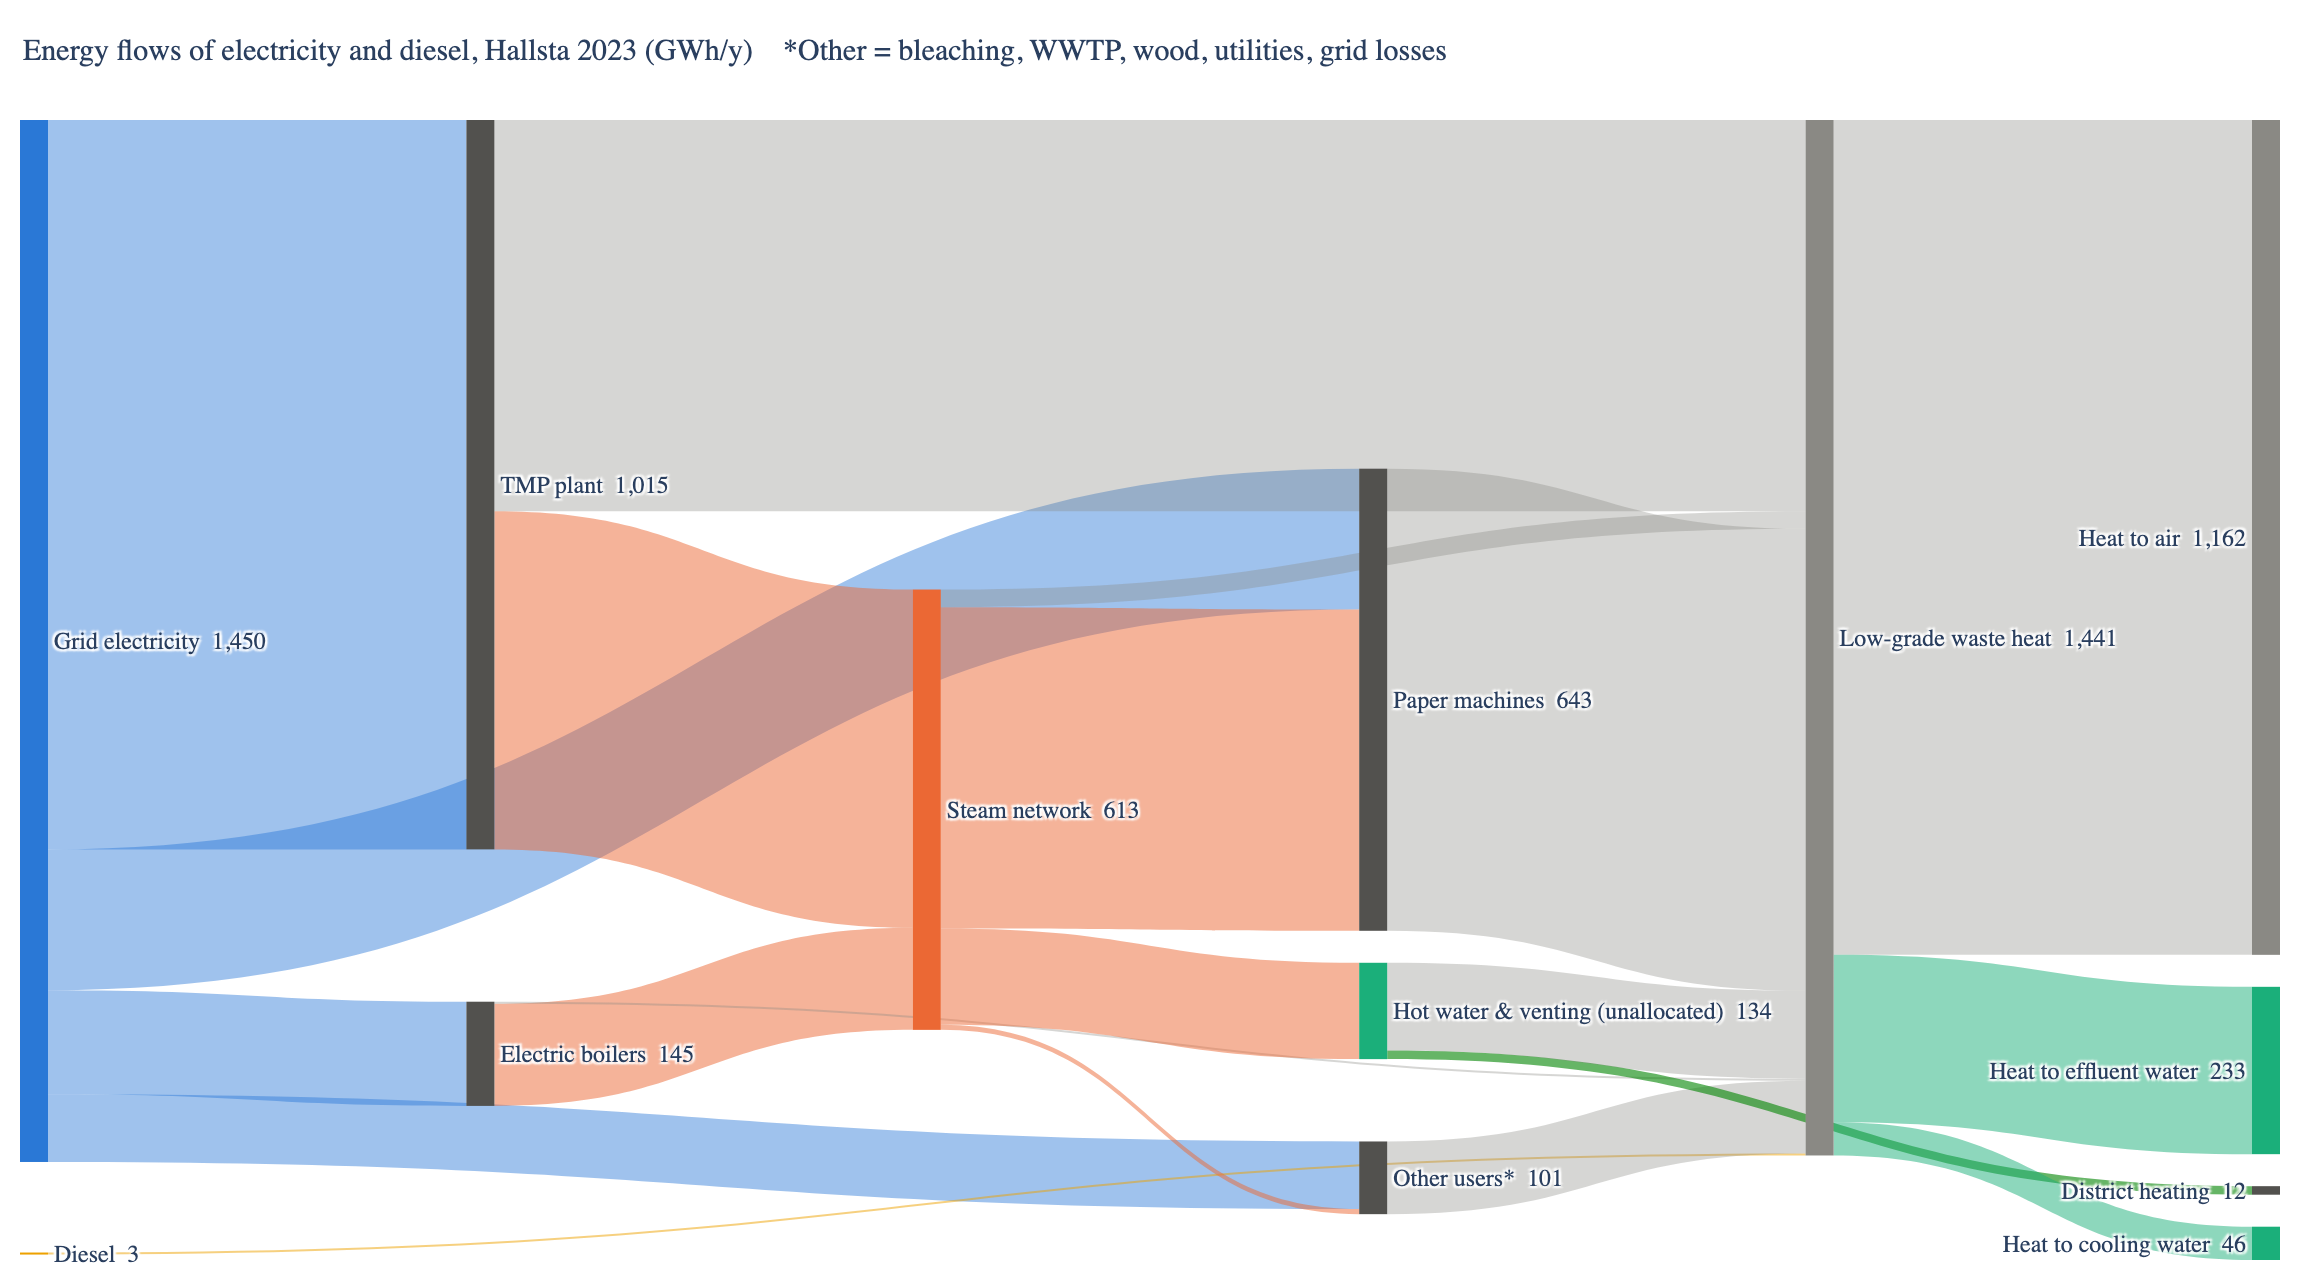

In [17]:
links_E, fig_E, png_ok = O.fig_sankey_energy(b)
display(links_E)
p = plotstyle.FIG_DIR / 'model_sankey_energy.png'
if png_ok and p.exists(): display(Image(p))
else: print('Static PNG skipped (no Chrome for kaleido). Interactive HTML saved: reports/figures/model_sankey_energy.html'); fig_E.show()

## 6. Exergy analysis and hotspots
**Intuition.** 1 kWh of electricity can run a motor. 1 kWh of 30 °C water can do almost nothing. Both are "1 kWh of energy", but their *usefulness* differs hugely. Exergy measures usefulness. Looking only at energy says "everything ends as heat, all equal". Exergy shows *where the useful part is thrown away* (**destroyed exergy**).

**Formulas.** Exergy per unit of heat released from $T_h$ down to $T_0$ (kelvin):
$$\frac{Ex}{Q} = 1 - \frac{T_0\,\ln(T_h/T_0)}{T_h - T_0}$$
For steam: $ex = \Delta h - T_0\,\Delta s$. Each process has one balance, **Ex_in = Ex_useful + Ex_waste + Ex_destroyed**, and efficiency $\psi = Ex_{useful}/Ex_{in}$.

**Worked intuition.** An electric boiler turns 1 kWh of pure-exergy electricity into steam. Its *energy* efficiency is about 98 %, but the steam holds only about 30 % of that exergy.

**Conventions (decision 14).** (i) Units with no useful output (paper machines, bleaching, WWTP, wood, utilities, grid) get ψ = 0 by convention: all their input counts as destroyed or waste. (ii) The useful exergy of "hot water" counts the *whole* steam residual at 60 °C, so its ψ is convention-dependent. (iii) Diesel is excluded from the exergy analysis (vehicles, outside the electricity–steam system, below 0.2 % of input). The ranking of the top three does not depend on these conventions; the ψ and improvement-potential columns do.

In [18]:
pd.Series({'Electricity': 1.0, 'Steam 3.4 bar → 90 °C condensate': b['fx_steam'], 'District heat 85/45 °C': b['f_DH'],
           'Unrecovered TMP heat, 80 °C': b['f_TMPw'], 'Hot water, 60 °C': b['f_HW'], 'PM waste heat, 50 °C': b['f_PMw'],
           'Effluent, 35 °C': b['f_eff']}, name='exergy per unit energy').to_frame().style.format('{:.3f}')

,exergy per unit energy
Electricity,1.000
Steam 3.4 bar → 90 °C condensate,0.315
District heat 85/45 °C,0.171
"Unrecovered TMP heat, 80 °C",0.111
"Hot water, 60 °C",0.084
"PM waste heat, 50 °C",0.070
"Effluent, 35 °C",0.047


In [19]:
HX = O.hotspots_table(b)
HX.sort_values('Destroyed', ascending=False).style.format({c: '{:,.1f}' for c in HX.columns if c not in ('psi','Energy rank','Exergy rank')} | {'psi': '{:.0%}'})

,Exergy in,Useful out,Waste out,Destroyed,psi,Improvement potential,Energy view: heat lost,Energy rank,Exergy rank
process,,,,,,,,,
TMP plant,"1,015.0",148.1,60.6,806.3,15%,740.4,544.3,2,1
Paper machines,336.6,0.0,44.8,291.8,0%,336.6,643.0,1,2
Electric boilers,145.0,44.7,0.0,100.3,31%,69.4,2.9,10,3
"Steam to hot water, heating and venting (unallocated)",42.2,11.3,0.0,30.9,27%,22.6,122.2,3,4
WWTP,21.9,0.0,0.0,21.9,0%,21.9,21.9,6,5
Bleaching,21.6,0.0,0.0,21.6,0%,21.6,21.6,7,6
Wood handling,20.2,0.0,0.0,20.2,0%,20.2,25.1,4,7
Utilities & other (residual / unexplained),18.1,0.0,0.0,18.1,0%,18.1,18.1,8,8
Internal grid losses,14.5,0.0,0.0,14.5,0%,14.5,14.5,9,9


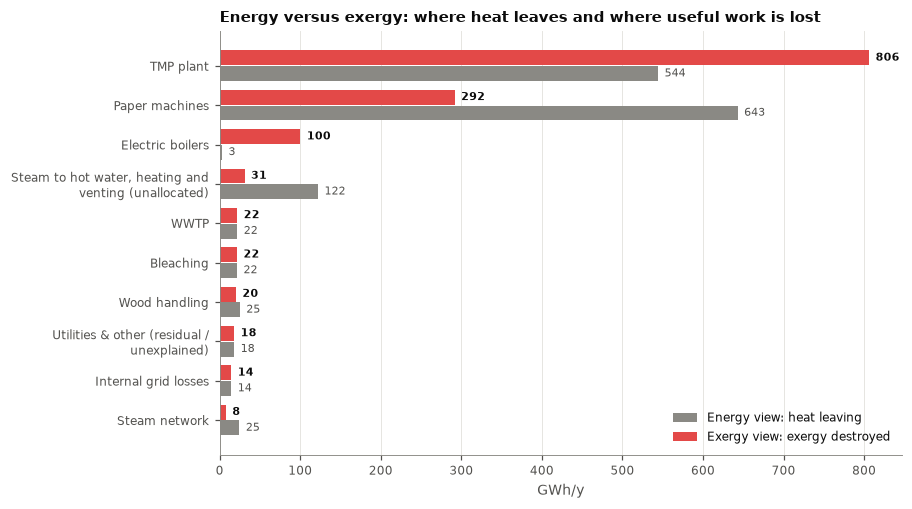

In [20]:
O.fig_hotspots(HX); plt.show()

Total exergy destroyed : 1,333 GWh/y (92% of input)
Electric boilers       : energy efficiency 98%, exergy efficiency 31%
TMP at 2,406 kWh/t vs Holmen normal 2,150: gap 108 GWh/y gross, 57 net (conditional on the 70 % share being right)


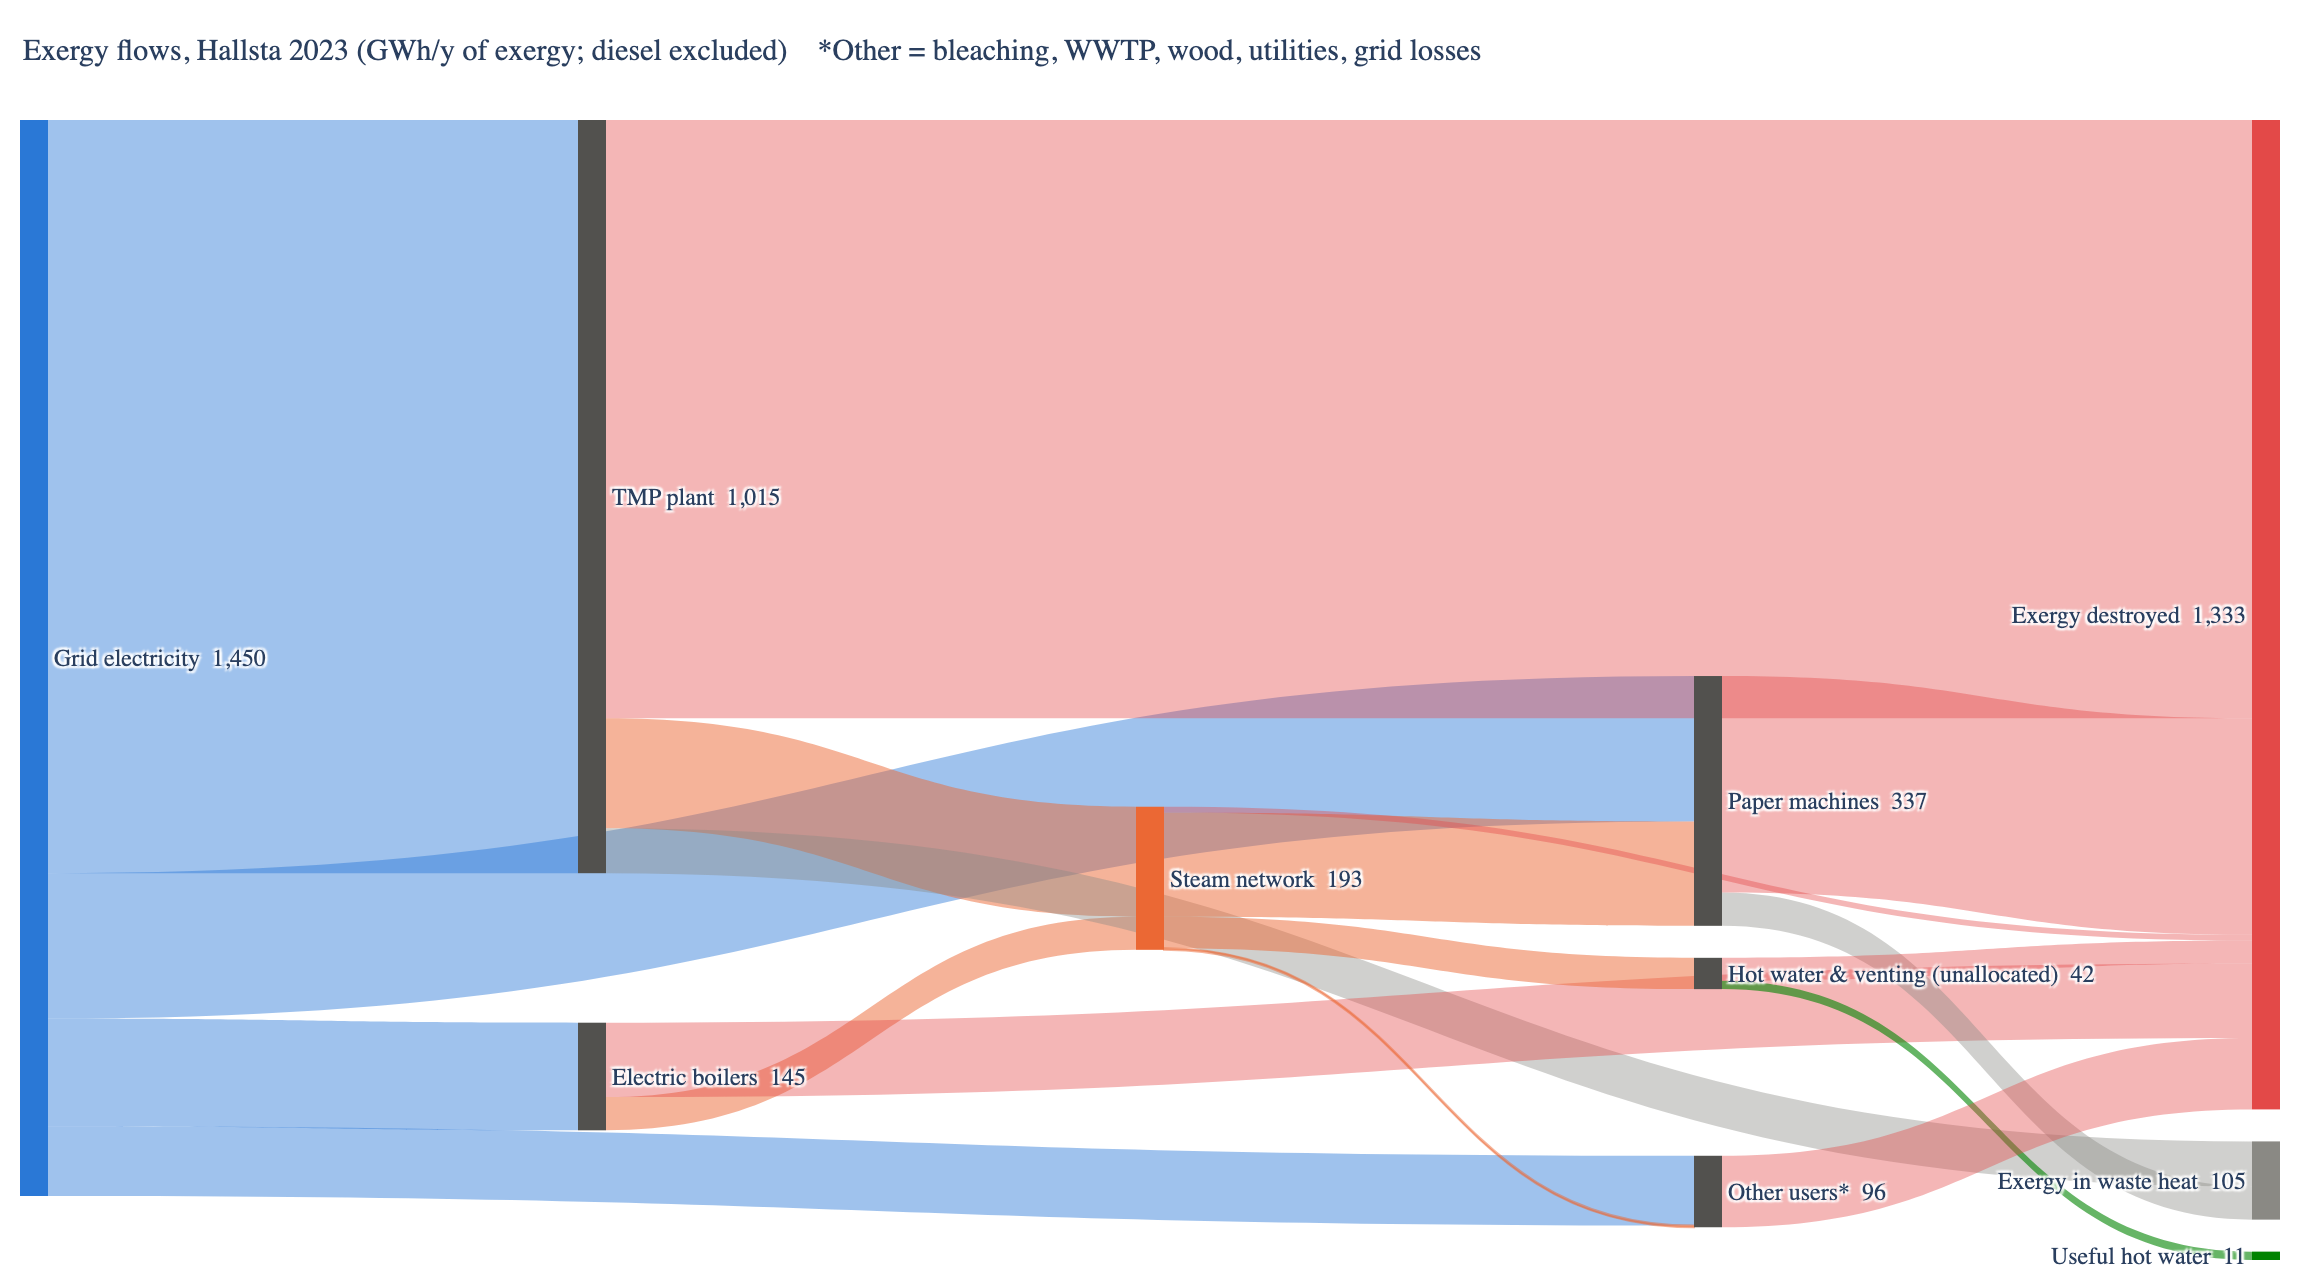

In [21]:
print(f"Total exergy destroyed : {b['Xdest_total']:,.0f} GWh/y ({b['Xdest_total']/E:.0%} of input)")
print(f"Electric boilers       : energy efficiency {b['eff_EB']:.0%}, exergy efficiency {b['psi|Electric boilers']:.0%}")
print(f"TMP at {b['SEC_TMP']:,.0f} kWh/t vs Holmen normal 2,150: gap {b['gap_SEC']:.0f} GWh/y gross, {b['gap_SEC_net']:.0f} net (conditional on the 70 % share being right)")
links_X, fig_X, png_ok_x = O.fig_sankey_exergy(b)
p = plotstyle.FIG_DIR / 'model_sankey_exergy.png'
if png_ok_x and p.exists(): display(Image(p))
else: print('Static PNG skipped (no Chrome). HTML saved: reports/figures/model_sankey_exergy.html')

## 7. Robustness: constrained Monte Carlo, sensitivity and scenarios
**Intuition.** Our inputs are estimates. Monte Carlo rolls the dice: draw a plausible value for every input, run the model, repeat 10,000 times. We then **keep only runs that agree with Holmen's data** (a *constrained* Monte Carlo): TMP supplies 70–90 % of the steam, the steam residual is not negative, and no process destroys negative exergy. The headline ranges are the P5/P50/P95 of the accepted runs; unconstrained results go in the appendix.

**Step 7a: ranges.** The quality class decides how wide each range is. The `DIST` table lives in `hallsta_mfa.model` (single copy). One shared draw of production hours drives TMP and PM steam.

In [22]:
pd.DataFrame(DIST, index=['distribution','a','b','c']).T

,distribution,a,b,c
E_tot,norm,1450,14.50,None
pulp_t,norm,421883,"4,218.83",None
paper_t,norm,444494,"4,444.94",None
DH_export,norm,11.88,0.59,None
diesel,norm,2.82,0.06,None
V_wwtp,norm,6679500,"333,975.00",None
V_ff,norm,609361,"60,936.10",None
V_cool,norm,"4,000,000.00","400,000.00",None
dT_cool,uni,5.00,15.00,None
sh_TMP,tri,0.65,0.70,0.75


**Step 7b: run 10,000 times** (`hallsta_mfa.mc.run_mc`, seed 2023).

In [23]:
mc = run_mc(10_000, 2023)
print(f'{mc.N:,} runs. Accepted (constrained): {mc.acceptance:.2%}')
print(mc.flags.mean().rename('share passing each condition').to_frame().T.to_string())
print(f'k-guard (named other-items scaled down) binds in {mc.k_binding_rate:.2%} of runs')

10,000 runs. Accepted (constrained): 99.18%
                              rec_ratio_in_range  st_HW_nonneg  Xdest_nonneg
share passing each condition                1.00          0.99          0.99
k-guard (named other-items scaled down) binds in 1.04% of runs


In [24]:
MC = O.mc_summary_table(mc, b); MC.drop(columns='key')

,base,P5,P50,P95,uncon_P5,uncon_P50,uncon_P95,acceptance_rate
quantity,,,,,,,,
Electricity TMP,"1,015.00",958.24,"1,007.21","1,053.45",958.40,"1,007.36","1,053.69",0.99
Electricity paper machines,195.90,173.45,210.83,258.51,173.47,210.90,258.64,0.99
Electricity electric boilers,145.00,94.16,132.38,158.33,93.69,132.21,158.24,0.99
Utilities & other (residual),18.10,4.85,20.64,38.74,4.87,20.64,38.74,0.99
Recovered TMP steam,470.68,420.67,470.92,523.05,419.84,470.65,522.88,0.99
Electric-boiler steam,142.10,91.77,129.12,154.58,91.38,128.91,154.55,0.99
Share of steam from TMP,0.77,0.75,0.79,0.84,0.75,0.79,0.84,0.99
"Steam to hot water, heating and venting (unallocated)",134.06,35.37,119.95,206.35,31.62,119.40,206.18,0.99
Heat to effluent water,232.87,193.19,232.32,273.66,193.19,232.32,273.67,0.99


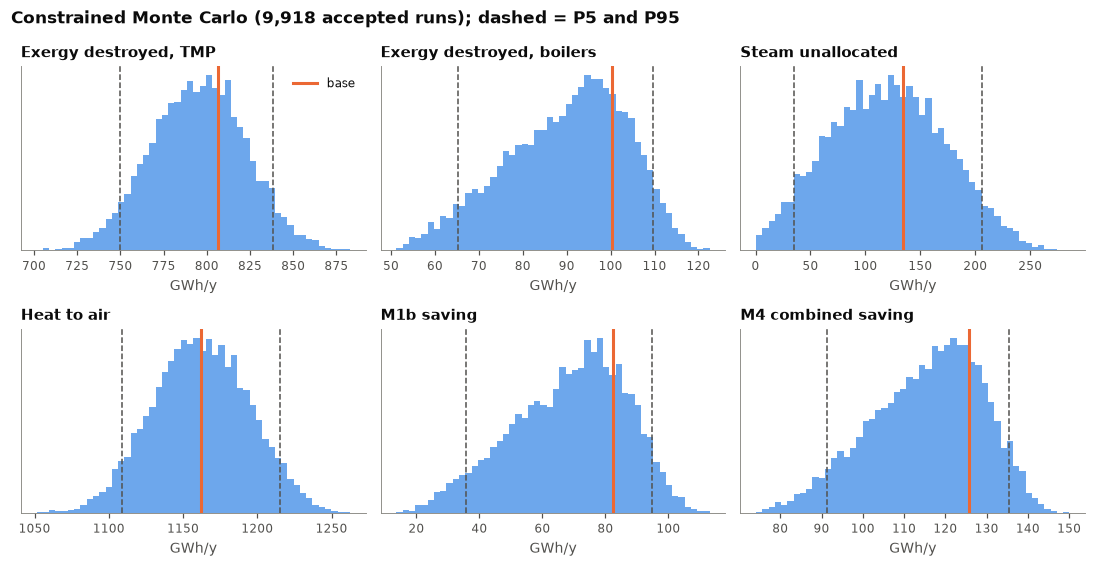

In [25]:
O.fig_mc_hist(mc, b); plt.show()

**Step 7c: is the hotspot ranking stable?** Rank the processes by exergy destroyed in each accepted run.

,rank_1,rank_2,rank_3,rank_4
process,,,,
TMP plant,100.0%,0.0%,0.0%,0.0%
Paper machines,0.0%,100.0%,0.0%,0.0%
Electric boilers,0.0%,0.0%,100.0%,0.0%
"Steam to hot water, heating and venting (unallocated)",0.0%,0.0%,0.0%,52.4%
Steam network,0.0%,0.0%,0.0%,0.0%
Bleaching,0.0%,0.0%,0.0%,4.6%
WWTP,0.0%,0.0%,0.0%,6.7%
Wood handling,0.0%,0.0%,0.0%,1.3%
Utilities & other (residual / unexplained),0.0%,0.0%,0.0%,23.6%


TMP > paper machines > electric boilers in 100.00% of accepted runs
Energy view: paper machines lose more heat than TMP in 95.6% of runs


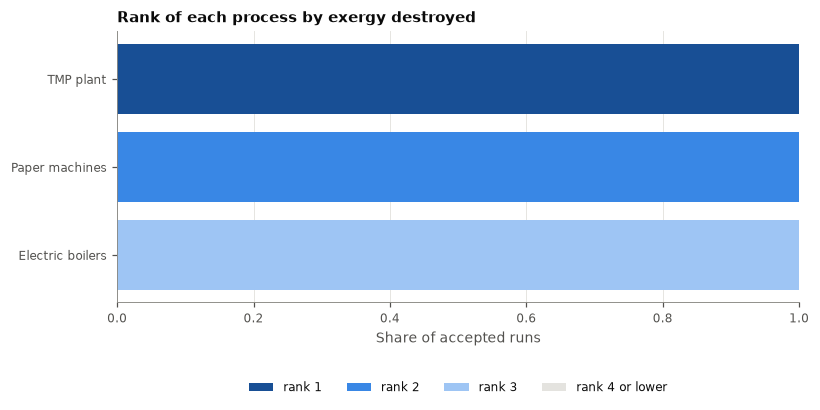

In [26]:
stab, top3 = O.rank_stability(mc)
display(stab.iloc[:, :4].style.format('{:.1%}'))
print(f'TMP > paper machines > electric boilers in {top3:.2%} of accepted runs')
Ya = mc.Y[mc.ok]
print(f"Energy view: paper machines lose more heat than TMP in {(Ya.PM_waste > Ya.TMP_waste).mean():.1%} of runs")
O.fig_rank(stab); plt.show()

**Step 7d: which inputs drive the results?** Spearman ρ measures how strongly an input and a result move together (accepted runs). Tornado: every input moved one at a time to **its own P5 and P95** (same convention for normal, triangular and uniform).

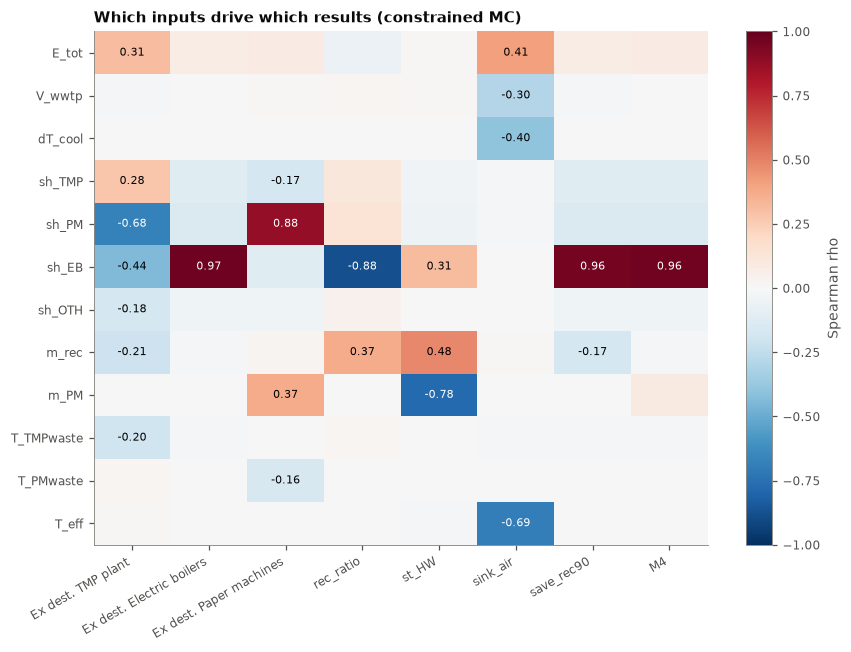

In [27]:
SP = O.spearman_table(mc); O.fig_spearman(SP); plt.show()

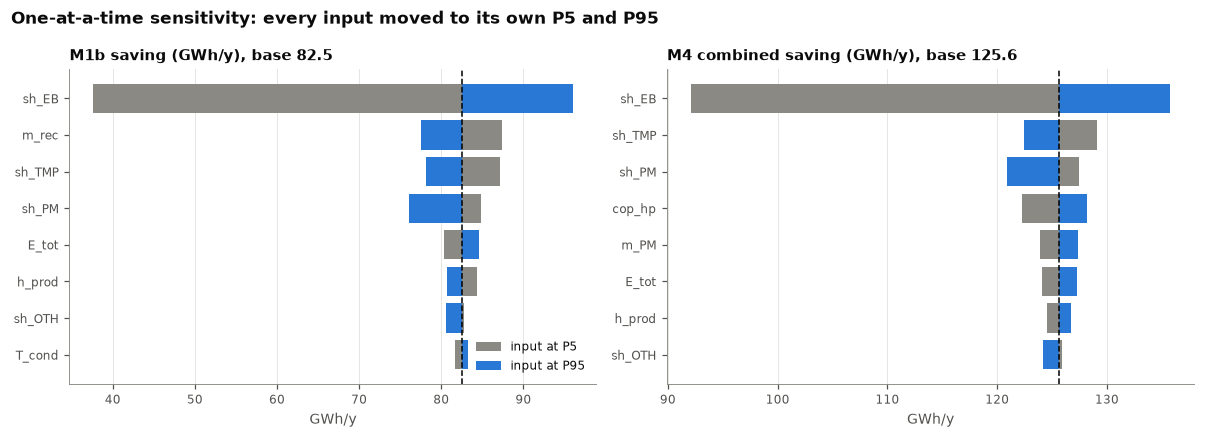

In [28]:
T = O.tornado_table(); O.fig_tornado(T); plt.show()

**Step 7e: scenarios.** Discrete cases a range cannot express. S5 = latent-heat-only steam basis (2.15 GJ/t); S6 = TMP at Holmen's normal SEC (2,150 kWh/t, the difference reallocated to *unexplained/other*).

In [29]:
sc = O.scenarios_table(); sc

,el_TMP,el_EB,el_util_unexplained,rec_ratio_pct,st_HW,eff_EB,y_EB_implied,sink_air,Xdest_TMP,Xdest_PM,Xdest_EB,Xdest_total,M1b_save_rec90,M4_combined,gap_SEC,top3_exergy
scenario,,,,,,,,,,,,,,,,
S0 Base,"1,015.00",145.00,18.10,76.81,134.06,0.98,1.50,"1,161.74",806.30,291.78,100.29,"1,333.31",82.47,125.64,107.95,TMP plant > Paper machines > Electric boilers
S1 2019 electricity split,"1,004.85",83.74,0.00,85.15,76.43,0.98,1.50,"1,161.74",797.28,375.08,57.92,"1,333.05",27.34,83.74,97.80,TMP plant > Paper machines > Electric boilers
S2 T0 = 25 C,"1,015.00",145.00,18.10,76.81,134.06,0.98,1.50,"1,161.74",842.85,291.37,106.54,"1,372.38",82.47,125.64,107.95,TMP plant > Paper machines > Electric boilers
S3 PM steam 110 t/h,"1,015.00",145.00,18.10,76.81,63.46,0.98,1.50,"1,161.74",806.30,309.07,100.29,"1,334.33",82.47,127.59,107.95,TMP plant > Paper machines > Electric boilers
S4 stress: 85 t/h recovery + 110 t/h PM,"1,015.00",145.00,18.10,73.79,-4.32,0.98,1.50,"1,161.74",820.66,309.07,100.29,"1,332.17",89.68,127.59,107.95,TMP plant > Paper machines > Electric boilers
S5 steam basis: latent heat only (2.15 GJ/t),"1,015.00",145.00,18.10,75.16,134.27,0.98,1.64,"1,161.74",801.78,294.47,96.06,"1,331.46",86.62,123.22,107.95,TMP plant > Paper machines > Electric boilers
"S6 TMP at Holmen's normal SEC (2,150 kWh/t)",907.05,145.00,126.05,76.81,134.06,0.98,1.50,"1,161.74",710.37,291.78,100.29,"1,345.33",82.47,125.64,0.00,TMP plant > Paper machines > Utilities & other
S7 effluent 39 C (32 K above sea),"1,015.00",145.00,18.10,76.81,134.06,0.98,1.50,"1,130.79",806.30,291.78,100.29,"1,333.31",82.47,125.64,107.95,TMP plant > Paper machines > Electric boilers
"S8 hours 8,760 h","1,015.00",145.00,14.20,80.12,133.55,0.98,1.50,"1,161.74",785.57,311.16,100.29,"1,338.28",72.07,131.71,107.95,TMP plant > Paper machines > Electric boilers


S4 gives a negative steam residual: Holmen's low recovery and high PM demand cannot both hold with 145 GWh of boiler electricity. S6 shows what moves if TMP really runs at its normal SEC: about 108 GWh of electricity becomes "unexplained/other", TMP exergy destruction falls by about the same amount (that exergy moves to 'unexplained/other', which is fully destroyed by convention), and total exergy destroyed rises by about 12 GWh because less heat leaves the TMP plant as waste-heat exergy.

## 8. Improvement measures
**Intuition.** The electric boilers are the *marginal* steam source: every tonne of steam saved or supplied some other way stops a boiler, and one MWh of boiler electricity makes about 0.98 MWh of steam. So each measure is first expressed as **steam displaced** (capped at the boiler steam), then divided by the boiler efficiency to get **electricity saved**.

| Measure | Steam displaced | Electricity saved |
|---|---|---|
| M1 TMP steam recovery +10 t/h | min(10 · h · Δh / 1000, st_EB) | / η |
| M1b recovery to 90 % of supply | min(0.9 · supply − st_rec, st_EB) | / η |
| M2 high-temperature heat pump replaces all boiler steam | st_EB | st_EB / η − st_EB / COP |
| M3 press dryness 48 → 50 % | (a) ΔW / W · st_PM; (b) ΔW · 2.4 GJ/t | / η |
| M4 combined | M3, then M1, then heat pump on what is left | EB − steam_left / COP |

**Press dryness (M3).** Dry solids S = paper · (1 − 0.07). Water into the dryer = S (1/d − 1). Water leaving with the paper = paper · 0.07. So evaporated water W(d) = S (1/d − 1) − 0.07 · paper. At d = 0.48 this is 416,700 t. Variant (a) assumes dryer steam proportional to the water evaporated (the draft's approach, base); variant (b) credits only the evaporation heat and is the low bound. Baseline dryness is triangular(45, 48, 51) %, so M3 is zero when the baseline is already at or above 50 %.

**COP.** Arpagaus et al. (2018) report COP 2.2–2.8 at a 70 K lift and 5.7–6.5 at 30 K (sink about 120 °C) for high-temperature heat pumps; lifting ~80 °C waste heat to 138 °C steam is a lift of about 58 K plus steam generation. Range used: uniform 2.5–3.5 (see `docs/assumptions.md`).

**Seasonal caveat.** The savings are *annual upper bounds*: they assume boilers run all year. Holmen says boilers cover the TMP shortfall; recovery at 70–90 % of need bounds this, which is why the ranges below come from the constrained Monte Carlo.

In [30]:
print('Intermediate: evaporated water at 48 % dryness =', f"{evaporated_water(BASE['paper_t'], 0.48, 0.07):,.0f} t/y; at 50 % =", f"{evaporated_water(BASE['paper_t'], 0.50, 0.07):,.0f} t/y")
MT = O.measures_table(mc, b)
MT[['measure','description','base_GWh','P5_GWh','P50_GWh','P95_GWh','base_MWh_t','P50_MWh_t','P50_newSEC_MWh_t','P50_pct_of_boiler_el']]

Intermediate: evaporated water at 48 % dryness = 416,713 t/y; at 50 % = 382,265 t/y


,measure,description,base_GWh,P5_GWh,P50_GWh,P95_GWh,base_MWh_t,P50_MWh_t,P50_newSEC_MWh_t,P50_pct_of_boiler_el
0,M1,M1 TMP steam recovery +10 t/h,48.03,46.16,48.30,50.43,0.11,0.11,3.15,36.54
1,M1b,M1b recovery raised to 90 % of supply,82.47,35.70,70.61,94.82,0.19,0.16,3.11,53.23
2,M2,M2 heat pump replaces all boiler steam,97.63,62.65,88.22,108.65,0.22,0.20,3.07,67.41
3,M3,M3 press dryness +2 points (48 -> 50 % at base; dryer steam prop. to water),37.72,32.37,37.89,43.57,0.08,0.09,3.18,28.98
4,M3b,"M3b press dryness, evaporation heat only (low bound)",23.43,21.66,23.56,25.76,0.05,0.05,3.21,17.93
5,M4,"M4 combined (M3, then M1, then heat pump)",125.64,91.36,117.02,135.41,0.28,0.26,3.00,88.82


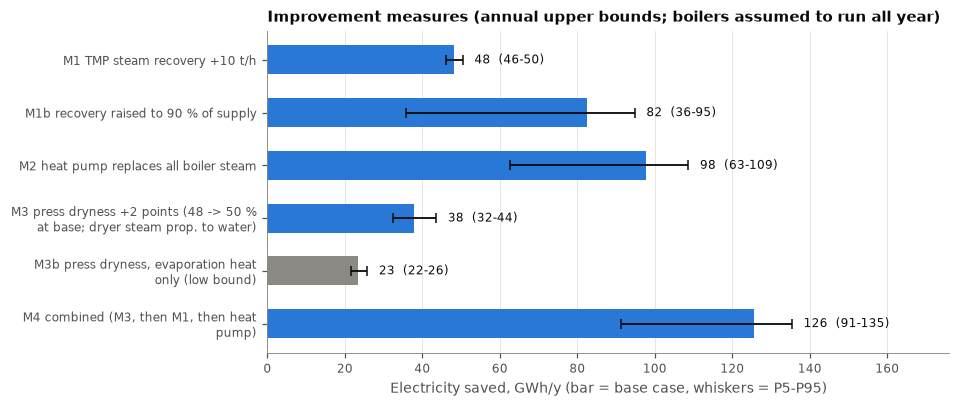

In [31]:
O.fig_measures(MT); plt.show()

## Conclusions

In [32]:
H = O.build_all(mc=mc, verbose=True)     # writes every table and figure in reports/
h = H['head']
f = lambda k: f"{h.loc[k,'base']:,.0f} ({h.loc[k,'P5']:,.0f}–{h.loc[k,'P95']:,.0f})"
rows = {m: h.loc[m] for m in h.index}
print(f"1. Flows: TMP {f('Electricity to TMP plant')} GWh, paper machines {f('Electricity to paper machines (excl. bleaching)')}, electric boilers {f('Electricity to electric boilers')}. "
      f"TMP heat recovery supplies {f('Share of steam from TMP')} % of steam.")
print(f"2. Sinks: heat to air {f('Heat to air')} GWh, effluent water {f('Heat to effluent water')}, cooling water {f('Heat to cooling water')}. District heat is 12 GWh.")
print(f"3. Hotspots: exergy destroyed {f('Exergy destroyed, total')} GWh; TMP {f('Exergy destroyed, TMP plant')}, paper machines {f('Exergy destroyed, paper machines')}, boilers {f('Exergy destroyed, electric boilers')}. Electric boilers are {b['eff_EB']:.0%} energy-efficient but {b['psi|Electric boilers']:.0%} exergy-efficient.")
print(f"4. Robustness: TMP > PM > boilers in {H['top3']:.1%} of accepted runs; {mc.acceptance:.1%} of runs accepted.")
print(f"5. Measures (GWh/y, base (P5–P95), annual upper bounds): M1 {f('M1 TMP steam recovery +10 t/h')}, M1b {f('M1b recovery to 90 % of supply')}, M2 {f('M2 heat pump replaces all boiler steam')}, M3 {f('M3 press dryness +2 points (48 to 50 %)')}, combined M4 {f('M4 combined')}.")
print(f"6. Not established: where {f('Steam to hot water, heating and venting (unallocated)')} GWh of steam goes, and why TMP specific energy ({b['SEC_TMP']:,.0f} kWh/t) exceeds Holmen's normal range.")

MC: N=10000, accepted 99.18%, k-guard binds in 1.04%; tables -> /Users/fadhil.1.mochammad/Documents/personal_repo/mfa-energy/reports/tables, figures -> /Users/fadhil.1.mochammad/Documents/personal_repo/mfa-energy/reports/figures
1. Flows: TMP 1,015 (958–1,053) GWh, paper machines 196 (173–259), electric boilers 145 (94–158). TMP heat recovery supplies 77 (75–84) % of steam.
2. Sinks: heat to air 1,162 (1,109–1,215) GWh, effluent water 233 (193–274), cooling water 46 (25–70). District heat is 12 GWh.
3. Hotspots: exergy destroyed 1,333 (1,304–1,354) GWh; TMP 806 (750–838), paper machines 292 (264–351), boilers 100 (65–110). Electric boilers are 98% energy-efficient but 31% exergy-efficient.
4. Robustness: TMP > PM > boilers in 100.0% of accepted runs; 99.2% of runs accepted.
5. Measures (GWh/y, base (P5–P95), annual upper bounds): M1 48 (46–50), M1b 82 (36–95), M2 98 (63–109), M3 38 (32–44), combined M4 126 (91–135).
6. Not established: where 134 (35–206) GWh of steam goes, and why TMP 